# 🌍 Ülke Ekonomilerini Kümeleme: Türkiye Kime Benziyor?

Ülkeleri "gelişmiş" ya da "gelişmekte olan" diye ikiye ayırmak kaba bir sınıflandırma. Bu defterde **gözetimsiz öğrenme** ile 134 ülkeyi 8 ekonomik göstergeye göre gruplara ayırıyor ve şu sorulara bakıyoruz:

1. Veri kendi başına kaç doğal grup öneriyor?
2. Bu gruplar ekonomik olarak neyi temsil ediyor?
3. **Türkiye hangi grupta ve ekonomik olarak en çok hangi ülkelere benziyor?**

**Yöntemler:** Standartlaştırma, K-Means, siluet analizi, temel bileşenler analizi (PCA), hiyerarşik kümeleme ile sağlamlık kontrolü.

**Veri:** Dünya Bankası, World Development Indicators. 2019–2023 ortalaması alındı; böylece tek bir yılın şoku (ör. 2020 pandemisi) sonucu bozmaz.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

RENK = {"mavi": "#1F5AA6", "kirmizi": "#C8102E", "sari": "#E3A21A", "yesil": "#1B7F4B",
        "mor": "#6A1B9A", "gri": "#8A8F98", "turkuaz": "#138D90"}
PALET = [RENK[k] for k in ["mavi", "kirmizi", "sari", "yesil", "mor", "turkuaz", "gri"]]
plt.rcParams.update({
    "figure.figsize": (10, 5), "figure.dpi": 110, "savefig.dpi": 150,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.titlesize": 13, "font.size": 10.5, "axes.prop_cycle": plt.cycler(color=PALET),
})
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

def kaydet(fig, ad):
    fig.tight_layout()
    fig.savefig(f"grafikler/{ad}.png", bbox_inches="tight", facecolor="white")

from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

from src.veri import yukle

TR_AD = {"TUR": "Türkiye", "USA": "ABD", "DEU": "Almanya", "FRA": "Fransa", "GBR": "İngiltere", "ITA": "İtalya",
         "ESP": "İspanya", "JPN": "Japonya", "KOR": "G. Kore", "CHN": "Çin", "IND": "Hindistan", "BRA": "Brezilya",
         "MEX": "Meksika", "RUS": "Rusya", "ARG": "Arjantin", "ZAF": "G. Afrika", "EGY": "Mısır", "IRN": "İran",
         "SAU": "S. Arabistan", "NGA": "Nijerya", "POL": "Polonya", "GRC": "Yunanistan", "CHE": "İsviçre",
         "NOR": "Norveç", "SWE": "İsveç", "IRL": "İrlanda", "SGP": "Singapur", "IDN": "Endonezya", "VNM": "Vietnam",
         "PAK": "Pakistan", "BGD": "Bangladeş", "ETH": "Etiyopya", "CHL": "Şili", "COL": "Kolombiya", "ROU": "Romanya",
         "HUN": "Macaristan", "BGR": "Bulgaristan", "AZE": "Azerbaycan", "KAZ": "Kazakistan", "UKR": "Ukrayna",
         "ISR": "İsrail", "MYS": "Malezya", "THA": "Tayland", "NLD": "Hollanda", "AUS": "Avustralya", "CAN": "Kanada",
         "PRT": "Portekiz", "CZE": "Çekya", "SRB": "Sırbistan", "GEO": "Gürcistan", "TUN": "Tunus", "MAR": "Fas",
         "JOR": "Ürdün", "LKA": "Sri Lanka", "PER": "Peru", "PHL": "Filipinler", "ARE": "BAE", "QAT": "Katar",
         "KWT": "Kuveyt", "DZA": "Cezayir", "KEN": "Kenya", "GHA": "Gana", "URY": "Uruguay", "HRV": "Hırvatistan",
         "SVK": "Slovakya", "LTU": "Litvanya", "ARM": "Ermenistan", "MNG": "Moğolistan", "BLR": "Belarus",
         "UZB": "Özbekistan", "TKM": "Türkmenistan", "KGZ": "Kırgızistan", "SLE": "Sierra Leone", "ZWE": "Zimbabve",
         "BEL": "Belçika", "AUT": "Avusturya", "DNK": "Danimarka", "HKG": "Hong Kong", "IRQ": "Irak", "COG": "Kongo",
         "PSE": "Filistin", "NAM": "Namibya", "BWA": "Botsvana", "LSO": "Lesotho", "SWZ": "Esvatini", "DJI": "Cibuti",
         "TZA": "Tanzanya", "MOZ": "Mozambik", "NPL": "Nepal", "SEN": "Senegal", "KHM": "Kamboçya", "RWA": "Ruanda",
         "TJK": "Tacikistan", "AFG": "Afganistan", "LBN": "Lübnan", "HTI": "Haiti", "SDN": "Sudan", "MDG": "Madagaskar",
         "CIV": "Fildişi Sahili", "CMR": "Kamerun", "NER": "Nijer", "MLI": "Mali", "BFA": "Burkina Faso", "MWI": "Malavi",
         "UGA": "Uganda", "AGO": "Angola", "LBY": "Libya", "MDA": "Moldova", "MRT": "Moritanya", "ZMB": "Zambiya",
         "DOM": "Dominik Cum.", "FIN": "Finlandiya", "SVN": "Slovenya", "EST": "Estonya", "LVA": "Letonya", "NZL": "Yeni Zelanda",
         "ECU": "Ekvador", "BOL": "Bolivya", "PRY": "Paraguay", "GTM": "Guatemala", "HND": "Honduras", "NIC": "Nikaragua",
         "BEN": "Benin", "GIN": "Gine", "OMN": "Umman", "BHR": "Bahreyn", "LAO": "Laos", "MMR": "Myanmar"}
ham = yukle()
ham = ham[(ham.nufus > 1e6)].dropna()
ham["ad"] = [TR_AD.get(k, a) for k, a in zip(ham.index, ham.ad)]
print(f"{len(ham)} ülke (nüfus > 1 milyon, 8 göstergesi tam)")
GOSTERGE = {"kisi_basi_gelir": "Kişi başı gelir ($, SGP)", "buyume": "Büyüme (%)", "enflasyon": "Enflasyon (%)",
            "issizlik": "İşsizlik (%)", "dis_ticaret": "Dış ticaret / GSYH (%)", "cari_denge": "Cari denge / GSYH (%)",
            "yatirim": "Yatırım / GSYH (%)", "yasam_suresi": "Yaşam süresi (yıl)"}
ham[list(GOSTERGE)].describe().round(1)

134 ülke (nüfus > 1 milyon, 8 göstergesi tam)


,kisi_basi_gelir,buyume,enflasyon,issizlik,dis_ticaret,cari_denge,yatirim,yasam_suresi
count,134.000,134.000,134.000,134.000,134.000,134.000,134.000,134.000
mean,"26,437.900",2.300,10.500,7.500,87.700,-1.200,24.000,73.100
std,"25,327.700",2.400,28.900,6.000,55.300,7.400,7.400,7.200
min,"1,488.300",-7.600,0.400,0.100,9.100,-22.600,-5.600,55.800
25%,"6,122.700",1.100,2.900,3.800,50.100,-4.600,19.200,67.100
50%,"17,192.600",2.400,4.400,5.500,75.900,-1.700,23.600,73.900
75%,"40,552.600",3.700,7.000,9.200,107.700,1.600,28.200,78.500
max,"127,295.500",7.500,253.900,33.300,369.000,26.100,42.600,85.000


## 1. Ön işleme

K-Means **mesafeye** dayanır. Bu yüzden değişkenlerin ölçeği ve dağılımı önemlidir:

- **Kişi başı gelir** ve **dış ticaret** çok çarpık dağılıyor (birkaç ülke çok yüksek), bu yüzden logaritmaları alınıyor.
- **Enflasyon** birkaç ülkede %100'ü aşıyor. İşaret korunarak $\text{sign}(x) \cdot \ln(1 + |x|)$ dönüşümü uygulanıyor.
- Ardından bütün değişkenler **standartlaştırılıyor** (ortalama 0, standart sapma 1). Böylece hiçbir gösterge sırf birimi büyük diye baskın çıkmıyor.

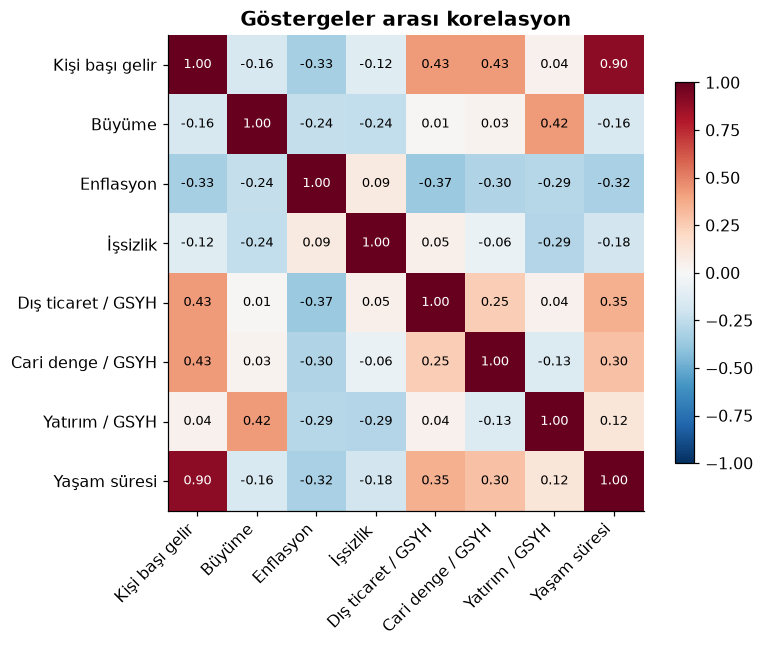

In [2]:
X = ham[list(GOSTERGE)].copy()
X["kisi_basi_gelir"] = np.log(X.kisi_basi_gelir)
X["dis_ticaret"] = np.log(X.dis_ticaret)
X["enflasyon"] = np.sign(X.enflasyon) * np.log1p(X.enflasyon.abs())
Z = pd.DataFrame(StandardScaler().fit_transform(X), index=X.index, columns=X.columns)

fig, ax = plt.subplots(figsize=(7.5, 6))
korelasyon = Z.corr()
im = ax.imshow(korelasyon, cmap="RdBu_r", vmin=-1, vmax=1)
etiket = [GOSTERGE[c].split(" (")[0] for c in Z.columns]
ax.set_xticks(range(8), etiket, rotation=45, ha="right"); ax.set_yticks(range(8), etiket)
for i in range(8):
    for j in range(8):
        ax.text(j, i, f"{korelasyon.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8.5,
                color="white" if abs(korelasyon.iloc[i, j]) > 0.55 else "black")
ax.grid(False); ax.set_title("Göstergeler arası korelasyon")
fig.colorbar(im, ax=ax, shrink=0.8)
kaydet(fig, "1_korelasyon")
plt.show()

Gelir ile yaşam süresi arasında çok güçlü bir ilişki var (zengin ülkelerde insanlar daha uzun yaşıyor). Enflasyon ise gelirle ters yönlü.

## 2. Kaç küme?

İki ölçüye bakıyoruz:
- **Dirsek yöntemi:** Küme içi toplam uzaklık (inertia) küme sayısı arttıkça azalır. Azalmanın yavaşladığı nokta iyi bir adaydır.
- **Siluet skoru:** Her ülkenin kendi kümesine ne kadar yakın, en yakın komşu kümeye ne kadar uzak olduğu. −1 ile 1 arasında değişir, yüksek olması iyidir.

$$s(i) = \frac{b(i) - a(i)}{\max\{a(i),\, b(i)\}}$$

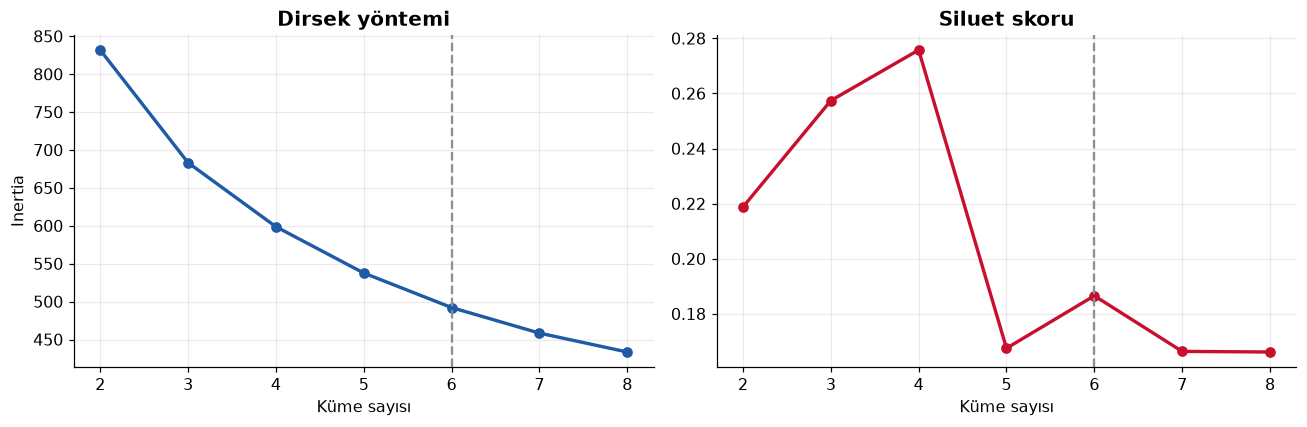

k,2,3,4,5,6,7,8
Siluet,0.219,0.257,0.276,0.168,0.187,0.166,0.166
Ward ile uyum (ARI),0.576,0.786,0.777,0.510,0.694,0.450,0.457


In [3]:
ks = range(2, 9)
inertia, siluet, ward_uyum = [], [], []
for k in ks:
    km = KMeans(k, n_init=50, random_state=42).fit(Z)
    inertia.append(km.inertia_)
    siluet.append(silhouette_score(Z, km.labels_))
    ward_uyum.append(adjusted_rand_score(km.labels_, AgglomerativeClustering(k, linkage="ward").fit_predict(Z)))

K = 6   # gerekçesi aşağıda

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(ks, inertia, marker="o", lw=2.2, color=RENK["mavi"]); ax1.set_title("Dirsek yöntemi"); ax1.set_xlabel("Küme sayısı"); ax1.set_ylabel("Inertia")
ax2.plot(ks, siluet, marker="o", lw=2.2, color=RENK["kirmizi"]); ax2.set_title("Siluet skoru"); ax2.set_xlabel("Küme sayısı")
for a in (ax1, ax2):
    a.axvline(K, color=RENK["gri"], ls="--")
kaydet(fig, "2_kume_sayisi")
plt.show()
pd.DataFrame({"Siluet": siluet, "Ward ile uyum (ARI)": ward_uyum}, index=pd.Index(ks, name="k")).round(3).T

**k seçimi bir yargı kararı.** Siluet skoru en yüksek k=4'te (0,28) ama orada ABD, Çin, Brezilya, Vietnam ve Türkiye dahil 75 ülke tek bir kümede toplanıyor; bu, analiz için bilgi vermiyor.
Siluet skorları 0,17–0,28 aralığında. Bu da ülkelerin keskin gruplara ayrılmadığını, ekonomilerin **sürekli bir yelpazede** dağıldığını söylüyor.

Bu yüzden **k = 6** seçildi:
- Her küme ekonomik olarak ayrı bir hikâye anlatıyor (aşağıda).
- 5–7 arasında farklı bir algoritmayla (Ward) en tutarlı sonuç bu (ARI 0,69).
- Siluet, k=5–8 arasında zaten birbirine yakın.

## 3. Kümeler

Kümeleri, yorumlamayı kolaylaştırmak için medyan kişi başı gelire göre sıralıyoruz.

In [4]:
km = KMeans(K, n_init=100, random_state=42).fit(Z)
sira = pd.Series(km.labels_, index=Z.index).map(
    ham.groupby(km.labels_).kisi_basi_gelir.median().rank(ascending=False).astype(int))
KUME_ADLARI = {1: "Yüksek gelirli açık ekonomiler", 2: "Orta-yüksek gelir, düşük enflasyon", 3: "Yüksek işsizlik", 4: "Yatırımla büyüyenler", 5: "Kriz ve yüksek enflasyon", 6: "Düşük gelirli ekonomiler"} or {i: f"Küme {i}" for i in range(1, K + 1)}
ham["kume"] = sira
ham["kume_adi"] = sira.map(KUME_ADLARI)

profil = ham.groupby("kume")[list(GOSTERGE)].median().rename(columns=GOSTERGE)
profil.insert(0, "ülke sayısı", ham.groupby("kume").size())
profil.index = profil.index.map(KUME_ADLARI)
profil.round(1)

,ülke sayısı,"Kişi başı gelir ($, SGP)",Büyüme (%),Enflasyon (%),İşsizlik (%),Dış ticaret / GSYH (%),Cari denge / GSYH (%),Yatırım / GSYH (%),Yaşam süresi (yıl)
kume,,,,,,,,,
Yüksek gelirli açık ekonomiler,17,"64,205.000",1.800,2.800,3.900,127.700,6.200,25.000,81.700
"Orta-yüksek gelir, düşük enflasyon",57,"31,062.100",2.000,4.700,6.200,82.500,-1.800,23.600,76.500
Yüksek işsizlik,12,"10,014.900",0.200,3.700,20.500,89.300,1.400,18.900,64.900
Yatırımla büyüyenler,17,"6,391.400",4.200,6.000,5.700,58.700,-4.600,34.200,70.400
Kriz ve yüksek enflasyon,7,"4,920.700",-4.100,70.000,10.600,37.400,-1.300,13.700,65.500
Düşük gelirli ekonomiler,24,"3,511.800",4.400,4.500,3.300,47.200,-4.000,20.400,63.600


In [5]:
for k in sorted(ham.kume.unique()):
    uyeler = ham[ham.kume == k].sort_values("nufus", ascending=False)
    print(f"{KUME_ADLARI[k]} ({len(uyeler)} ülke): " + ", ".join(uyeler.ad.head(14)) + (" ..." if len(uyeler) > 14 else ""))

Yüksek gelirli açık ekonomiler (17 ülke): Almanya, G. Kore, Hollanda, Belçika, İsveç, BAE, Avusturya, İsviçre, Hong Kong, Danimarka, Singapur, Norveç, İrlanda, Kuveyt ...
Orta-yüksek gelir, düşük enflasyon (57 ülke): ABD, Brezilya, Rusya, Meksika, Japonya, Vietnam, Tayland, Fransa, İngiltere, İtalya, Kolombiya, İspanya, Kanada, Polonya ...
Yüksek işsizlik (12 ülke): G. Afrika, Irak, Angola, Tunus, Libya, Kongo, Filistin, Namibya, Botsvana, Lesotho, Esvatini, Cibuti
Yatırımla büyüyenler (17 ülke): Hindistan, Çin, Endonezya, Bangladeş, Türkiye, Tanzanya, Cezayir, Özbekistan, Mozambik, Nepal, Senegal, Kamboçya, Ruanda, Tacikistan ...
Kriz ve yüksek enflasyon (7 ülke): Sudan, Arjantin, Ukrayna, Afganistan, Zimbabve, Haiti, Lübnan
Düşük gelirli ekonomiler (24 ülke): Pakistan, Etiyopya, Filipinler, Mısır, Kenya, Uganda, Gana, Madagaskar, Fildişi Sahili, Kamerun, Nijer, Mali, Burkina Faso, Malavi ...


## 4. İki boyutta görmek: Temel Bileşenler Analizi (PCA)

8 boyutlu veriyi, varyansı en çok koruyan iki eksene indirgiyoruz. Oklar, her göstergenin bu iki eksene katkısını gösteriyor (*biplot*).

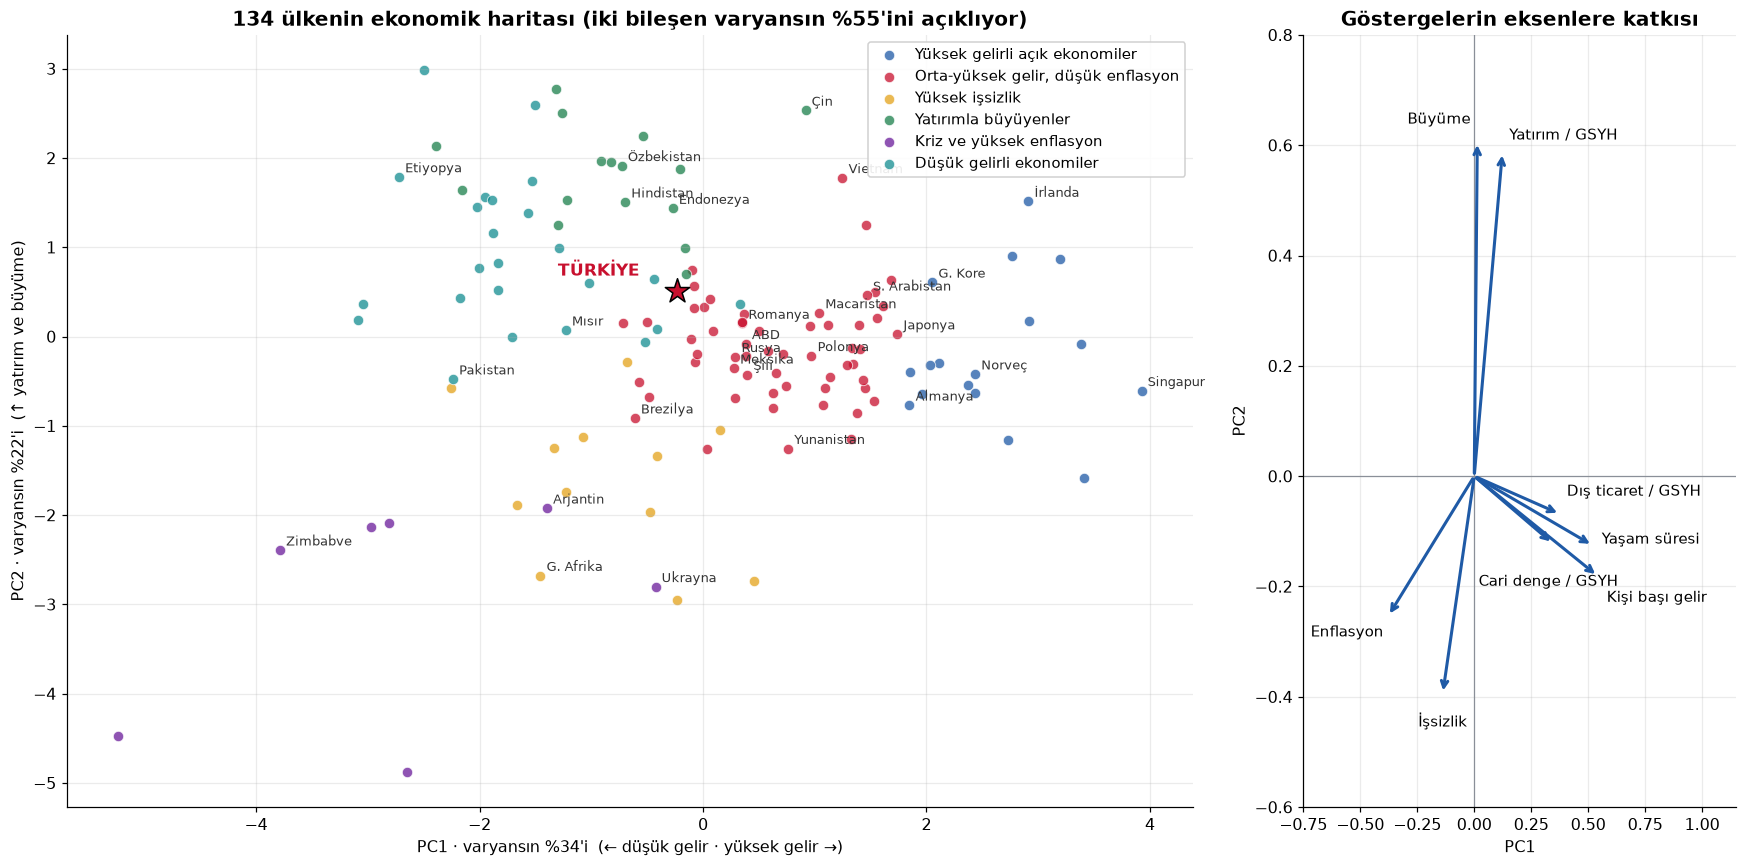

,PC1,PC2
"Kişi başı gelir ($, SGP)",0.540,-0.180
Büyüme (%),0.010,0.610
Enflasyon (%),-0.380,-0.250
İşsizlik (%),-0.140,-0.390
Dış ticaret / GSYH (%),0.380,-0.070
Cari denge / GSYH (%),0.340,-0.120
Yatırım / GSYH (%),0.120,0.590
Yaşam süresi (yıl),0.520,-0.130


In [6]:
pca = PCA(2).fit(Z)
P = pd.DataFrame(pca.transform(Z), index=Z.index, columns=["PC1", "PC2"])
aciklanan = pca.explained_variance_ratio_

fig, (ax, axy) = plt.subplots(1, 2, figsize=(16, 8), gridspec_kw={"width_ratios": [2.6, 1]})
for k in sorted(ham.kume.unique()):
    m = ham.kume == k
    ax.scatter(P.loc[m, "PC1"], P.loc[m, "PC2"], s=46, alpha=0.75, color=PALET[k - 1], label=KUME_ADLARI[k], edgecolor="white", lw=0.6)
goster = ["USA", "DEU", "JPN", "CHN", "IND", "BRA", "RUS", "ARG", "EGY", "IRN", "SAU", "NGA", "POL", "GRC", "SGP",
          "IRL", "MEX", "ZAF", "IDN", "VNM", "NOR", "KOR", "ETH", "PAK", "ROU", "HUN", "CHL", "UKR", "ZWE", "UZB"]
for kod in [g for g in goster if g in P.index]:
    ax.annotate(ham.loc[kod, "ad"], P.loc[kod], fontsize=8.5, xytext=(4, 3), textcoords="offset points", color="#333")
ax.scatter(*P.loc["TUR"], s=280, marker="*", color=RENK["kirmizi"], edgecolor="black", zorder=5)
ax.annotate("TÜRKİYE", P.loc["TUR"], fontsize=11, fontweight="bold", xytext=(-78, 10), textcoords="offset points", color=RENK["kirmizi"])
ax.set_xlabel(f"PC1 · varyansın %{100 * aciklanan[0]:.0f}'i  (← düşük gelir · yüksek gelir →)")
ax.set_ylabel(f"PC2 · varyansın %{100 * aciklanan[1]:.0f}'i  (↑ yatırım ve büyüme)")
ax.set_title(f"134 ülkenin ekonomik haritası (iki bileşen varyansın %{100 * aciklanan.sum():.0f}'ini açıklıyor)")
ax.legend(frameon=True, framealpha=0.9, loc="upper right", fontsize=9.5)

ETIKET_YERI = {"buyume": (-0.03, 0.04, "right"), "yatirim": (0.03, 0.03, "left"), "dis_ticaret": (0.03, 0.04, "left"),
               "cari_denge": (-0.02, -0.07, "center"), "yasam_suresi": (0.04, 0.01, "left"),
               "kisi_basi_gelir": (0.04, -0.04, "left"), "enflasyon": (-0.02, -0.03, "right"), "issizlik": (0.0, -0.05, "center")}
for i, c in enumerate(Z.columns):
    x, y = pca.components_[0, i], pca.components_[1, i]
    dx, dy, ha = ETIKET_YERI[c]
    axy.annotate("", (x, y), (0, 0), arrowprops=dict(arrowstyle="->", color=RENK["mavi"], lw=2))
    axy.text(x + dx, y + dy, GOSTERGE[c].split(" (")[0], fontsize=9.5, ha=ha, va="center")
axy.set_xlim(-0.75, 1.15); axy.set_ylim(-0.6, 0.8)
axy.axhline(0, color=RENK["gri"], lw=0.8); axy.axvline(0, color=RENK["gri"], lw=0.8)
axy.set_title("Göstergelerin eksenlere katkısı"); axy.set_xlabel("PC1"); axy.set_ylabel("PC2")
kaydet(fig, "3_pca_harita")
plt.show()
pd.DataFrame(pca.components_.T, index=[GOSTERGE[c] for c in Z.columns], columns=["PC1", "PC2"]).round(2)

## 5. Türkiye kime benziyor?

Standartlaştırılmış 8 boyutlu uzayda Türkiye'ye **Öklid uzaklığı** en küçük olan ülkeler:

$$d(\text{TR}, j) = \sqrt{\sum_{g=1}^{8} (z_{TR,g} - z_{j,g})^2}$$

In [7]:
uzaklik = np.sqrt(((Z - Z.loc["TUR"]) ** 2).sum(axis=1)).drop("TUR").sort_values()
komsular = pd.DataFrame({"ülke": ham.loc[uzaklik.index[:10], "ad"], "uzaklık": uzaklik.head(10).round(2),
                         "küme": ham.loc[uzaklik.index[:10], "kume_adi"]})
print(f"Türkiye'nin kümesi: {ham.loc['TUR', 'kume_adi']}")
komsular.reset_index(drop=True)

Türkiye'nin kümesi: Yatırımla büyüyenler


,ülke,uzaklık,küme
0,Özbekistan,2.200,Yatırımla büyüyenler
1,Kazakistan,2.350,"Orta-yüksek gelir, düşük enflasyon"
2,Gürcistan,2.620,"Orta-yüksek gelir, düşük enflasyon"
3,Sırbistan,2.640,"Orta-yüksek gelir, düşük enflasyon"
4,Dominik Cum.,2.660,"Orta-yüksek gelir, düşük enflasyon"
5,Moğolistan,2.670,Yatırımla büyüyenler
6,Romanya,2.770,"Orta-yüksek gelir, düşük enflasyon"
7,Cezayir,2.850,Yatırımla büyüyenler
8,Mısır,2.920,Düşük gelirli ekonomiler
9,Hindistan,2.920,Yatırımla büyüyenler


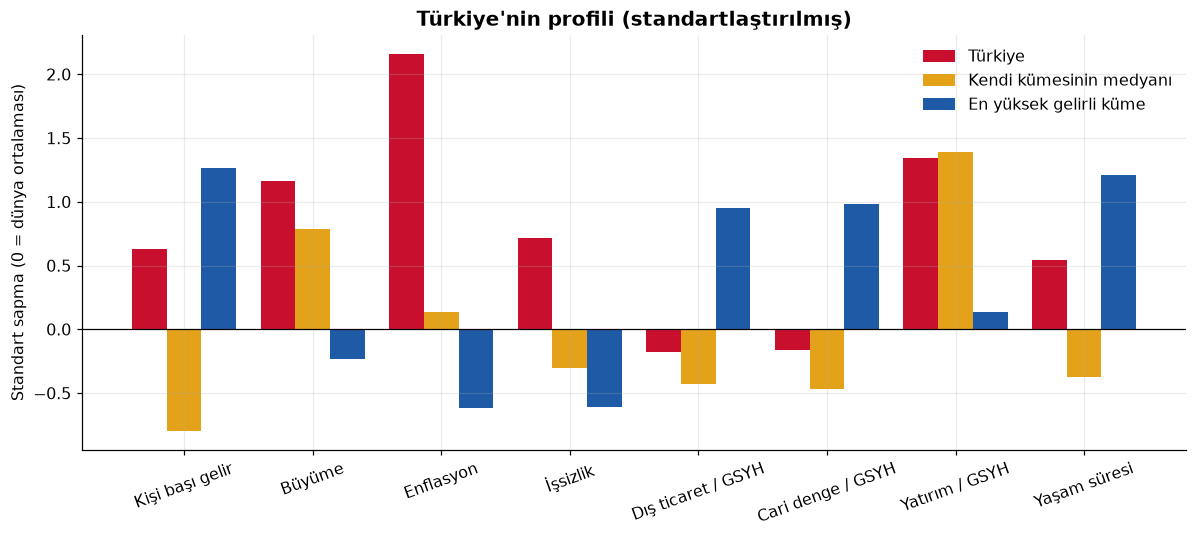

,Türkiye (2019–2023 ort.)
"Kişi başı gelir ($, SGP)","31,682.700"
Büyüme (%),5.100
Enflasyon (%),34.600
İşsizlik (%),11.700
Dış ticaret / GSYH (%),67.600
Cari denge / GSYH (%),-2.400
Yatırım / GSYH (%),33.800
Yaşam süresi (yıl),76.900


In [8]:
tr_kume = ham.loc["TUR", "kume"]
karsilastir = pd.DataFrame({
    "Türkiye": Z.loc["TUR"],
    "Kendi kümesinin medyanı": Z[ham.kume == tr_kume].median(),
    "En yüksek gelirli küme": Z[ham.kume == 1].median(),
}).rename(index=lambda c: GOSTERGE[c].split(" (")[0])

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(karsilastir))
for i, (ad, renk) in enumerate(zip(karsilastir.columns, [RENK["kirmizi"], RENK["sari"], RENK["mavi"]])):
    ax.bar(x + (i - 1) * 0.27, karsilastir[ad], 0.27, color=renk, label=ad)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x, karsilastir.index, rotation=20)
ax.set_ylabel("Standart sapma (0 = dünya ortalaması)")
ax.set_title("Türkiye'nin profili (standartlaştırılmış)")
ax.legend(frameon=False)
kaydet(fig, "4_turkiye_profil")
plt.show()
ham.loc["TUR", list(GOSTERGE)].rename(GOSTERGE).round(1).to_frame("Türkiye (2019–2023 ort.)")

## 6. Sağlamlık kontrolü

Kümeler gerçekten veride mi, yoksa K-Means'in bir yan ürünü mü? Tamamen farklı çalışan **hiyerarşik kümeleme (Ward)** ile aynı veriyi gruplayıp iki sonucu **Düzeltilmiş Rand İndeksi** ile karşılaştırıyoruz (1 = birebir aynı, 0 = rastgele).

In [9]:
ward = AgglomerativeClustering(K, linkage="ward").fit_predict(Z)
ari = adjusted_rand_score(km.labels_, ward)
tohumlar = [adjusted_rand_score(km.labels_, KMeans(K, n_init=10, random_state=s).fit_predict(Z)) for s in range(20)]
print(f"K-Means ile Ward uyumu (ARI): {ari:.2f}")
print(f"Farklı başlangıçlarla K-Means tutarlılığı (ARI ort.): {np.mean(tohumlar):.2f}")
print(f"Türkiye'nin Ward kümesindeki ülkeler: " + ", ".join(ham.ad[ward == ward[list(Z.index).index('TUR')]].head(20)))

K-Means ile Ward uyumu (ARI): 0.69
Farklı başlangıçlarla K-Means tutarlılığı (ARI ort.): 0.71
Türkiye'nin Ward kümesindeki ülkeler: Bangladeş, Cezayir, Endonezya, Hindistan, Kırgızistan, Kamboçya, Moldova, Moğolistan, Mozambik, Moritanya, Nepal, Senegal, Tacikistan, Türkiye, Özbekistan, Zambiya


## 7. Sonuçlar

| Küme | Ülke | Tanımlayıcı özellik | Örnekler |
|---|---|---|---|
| Yüksek gelirli açık ekonomiler | 17 | Gelir 64 bin $, dış ticaret GSYH'nin %128'i, cari fazla | Almanya, G. Kore, İsviçre, Singapur |
| Orta-yüksek gelir, düşük enflasyon | 57 | Gelir 31 bin $, enflasyon %4,7 | ABD, Japonya, Brezilya, Polonya |
| Yüksek işsizlik | 12 | İşsizlik %20,5 | G. Afrika, Irak, Tunus |
| **Yatırımla büyüyenler** | 17 | Yatırım GSYH'nin %34'ü, büyüme %4,2 | **Türkiye**, Çin, Hindistan, Endonezya |
| Kriz ve yüksek enflasyon | 7 | Enflasyon %70, küçülme | Arjantin, Ukrayna, Lübnan |
| Düşük gelirli ekonomiler | 24 | Gelir 3,5 bin $, yaşam süresi 64 yıl | Pakistan, Etiyopya, Kenya |

1. **Ekonomiler keskin gruplara ayrılmıyor.** Siluet skorları düşük (0,17–0,28). Ülkeler sürekli bir yelpazede dağılıyor, kümeler bu yelpazeyi okumayı kolaylaştıran bir araç.
2. **Haritanın iki ekseni:** Birinci bileşen *refah* (gelir, yaşam süresi, dışa açıklık; karşısında enflasyon), ikinci bileşen *büyüme modeli* (yatırım ve büyüme; karşısında işsizlik). İkisi birlikte varyansın %55'ini açıklıyor.
3. **Türkiye iki dünya arasında.** Büyüme modeliyle (GSYH'nin %34'ü yatırım, %5 büyüme, cari açık) Çin, Hindistan ve Endonezya ile aynı kümede. Ama kişi başı geliri kümesinin medyanının ~5 katı, yaşam süresi de orta-yüksek gelirli ülkelere yakın. Haritada iki kümenin tam sınırında duruyor.
4. **Türkiye'yi ayıran şey enflasyon.** %34,6 ile dünya ortalamasının 2,2 standart sapma üstünde; kriz ekonomileri dışındaki en yüksek değerlerden biri.
5. **En yakın komşular:** Özbekistan, Kazakistan, Gürcistan, Sırbistan ve Romanya. Yani bölgesindeki, hızlı büyüyen geçiş ekonomileri.
6. **Sonuç sağlam.** Tamamen farklı çalışan Ward yöntemi de Türkiye'yi aynı büyüme odaklı grupla eşleştiriyor (iki yöntemin uyumu ARI = 0,69).

### Sınırlılıklar
- Sonuç seçilen 8 göstergeye bağlı. Örneğin kamu borcu, eğitim ya da kurumsal kalite eklenirse kümeler değişebilir.
- 2019–2023 ortalaması pandemi yıllarını da içeriyor.
- K-Means küresel ve benzer büyüklükte kümeler varsayar. Gerçek ekonomik gruplar böyle olmak zorunda değil.
